# 32. Matrix Inequalities
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Golden–Thompson in practice: for $2000$ random pairs of $4\times4$ Hermitian matrices of comparable size, the ratio $\mathrm{tr}(e^Ae^B)/\mathrm{tr}\,e^{A+B}$ is always at least $1$ and grows with the size of the commutator $\lVert[A,B]\rVert_F$; for nearly commuting pairs it is close to $1$.

Text(0, 0.5, '$\\mathrm{tr}(e^Ae^B)\\,/\\,\\mathrm{tr}\\,e^{A+B}$')

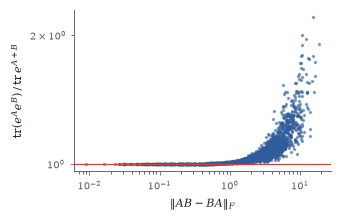

In [2]:
from scipy.linalg import expm
rng = np.random.default_rng(0); rows = []
for _ in range(2000):
    s = rng.uniform(0.1, 1.2); Xa, Xb = rng.normal(size=(4, 4)) * s, rng.normal(size=(4, 4)) * s; A4, B4 = (Xa + Xa.T) / 2, (Xb + Xb.T) / 2
    rows.append((np.linalg.norm(A4 @ B4 - B4 @ A4), np.trace(expm(A4) @ expm(B4)).real / np.trace(expm(A4 + B4)).real))
rows = np.array(rows)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.9))
ax.scatter(rows[:, 0], rows[:, 1], s=1.5, color=BLUE, alpha=0.5); ax.axhline(1, color=RED, lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\|AB-BA\|_F$"); ax.set_ylabel(r"$\mathrm{tr}(e^Ae^B)\,/\,\mathrm{tr}\,e^{A+B}$")

The Lieb–Thirring ratio $\mathrm{tr}\big((B^{1/2}AB^{1/2})^r\big)\,/\,\mathrm{tr}(A^rB^r)$ as a function of $r$ for $30$ random pairs of $5\times5$ positive matrices. All curves pass through $1$ at $r=1$ (where both sides are $\mathrm{tr}(AB)$), lie below $1$ for $r>1$ and above $1$ for $r<1$, as Araki's log-majorization predicts.

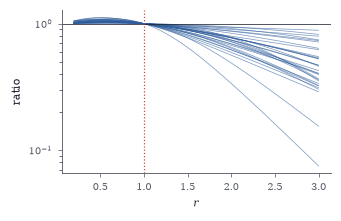

In [3]:
rng = np.random.default_rng(1); rs = np.linspace(0.2, 3, 60)
def mpow(M, p): lam, U = np.linalg.eigh(M); return (U * np.clip(lam, 0, None) ** p) @ U.T
fig, ax = plt.subplots(figsize=(W * 0.65, 1.9))
for _ in range(30):
    Xa, Xb = rng.normal(size=(5, 5)), rng.normal(size=(5, 5)); A5, B5 = Xa @ Xa.T / 5, Xb @ Xb.T / 5; Bh = mpow(B5, 0.5); C5 = Bh @ A5 @ Bh
    ax.plot(rs, [np.trace(mpow(C5, r)) / np.trace(mpow(A5, r) @ mpow(B5, r)) for r in rs], color=BLUE, lw=0.5, alpha=0.6)
ax.axhline(1, color=INK, lw=0.5); ax.axvline(1, color=RED, ls=":", lw=0.8); ax.set_xlabel("$r$"); ax.set_ylabel("ratio"); ax.set_yscale("log")

The Heinz function $h(\nu)=\lVert A^\nu XB^{1-\nu}+A^{1-\nu}XB^\nu\rVert$ for random positive $A,B$ and random $X$ ($6\times6$), in the operator norm (blue) and the trace norm (red), each normalized by its value at $\nu=0$, which is $\lVert AX+XB\rVert$. Both are convex, symmetric about $\nu=\frac12$, with minimum $2\lVert A^{1/2}XB^{1/2}\rVert$ there (dots).

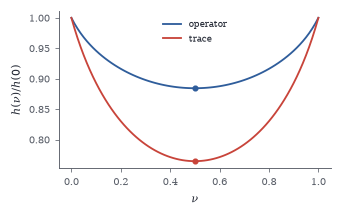

In [4]:
rng = np.random.default_rng(3); Xa, Xb = rng.normal(size=(6, 6)), rng.normal(size=(6, 6)); Ah, Bh6 = Xa @ Xa.T / 6, Xb @ Xb.T / 6; X6 = rng.normal(size=(6, 6))
nus = np.linspace(0, 1, 81)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
for o, col in [(2, BLUE), ("nuc", RED)]:
    hv = np.array([np.linalg.norm(mpow(Ah, v) @ X6 @ mpow(Bh6, 1 - v) + mpow(Ah, 1 - v) @ X6 @ mpow(Bh6, v), o) for v in nus]); ax.plot(nus, hv / hv[0], color=col, label="operator" if o == 2 else "trace")
    ax.plot(0.5, 2 * np.linalg.norm(mpow(Ah, 0.5) @ X6 @ mpow(Bh6, 0.5), o) / hv[0], "o", color=col, ms=3)
ax.set_xlabel(r"$\nu$"); ax.set_ylabel(r"$h(\nu)/h(0)$"); ax.legend(fontsize=6)

How large are commutators? For $3000$ random pairs of $5\times5$ matrices of each kind, the ratio $\lVert AB-BA\rVert/(\lVert A\rVert\lVert B\rVert)$ in the operator norm: general real matrices (grey) stay below the trivial bound $2$, positive semidefinite pairs (blue) below Kittaneh's bound $\frac12$ (dashed). Random matrices are far from the extremes, which are attained only by special pairs.

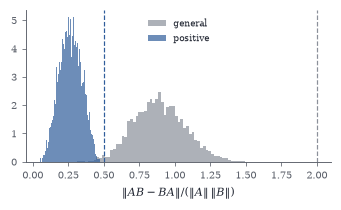

In [5]:
rng = np.random.default_rng(4); gen, psd = [], []
for _ in range(3000):
    Ag, Bg = rng.normal(size=(5, 5)), rng.normal(size=(5, 5)); gen.append(np.linalg.norm(Ag @ Bg - Bg @ Ag, 2) / (np.linalg.norm(Ag, 2) * np.linalg.norm(Bg, 2)))
    Ap, Bp = Ag @ Ag.T, Bg @ Bg.T; psd.append(np.linalg.norm(Ap @ Bp - Bp @ Ap, 2) / (np.linalg.norm(Ap, 2) * np.linalg.norm(Bp, 2)))
fig, ax = plt.subplots(figsize=(W * 0.65, 1.8))
ax.hist(gen, bins=60, color=GRAY, alpha=0.7, density=True, label="general"); ax.hist(psd, bins=60, color=BLUE, alpha=0.7, density=True, label="positive")
ax.axvline(0.5, color=BLUE, ls="--", lw=0.8); ax.axvline(2, color=GRAY, ls="--", lw=0.8); ax.set_xlabel(r"$\|AB-BA\|/(\|A\|\,\|B\|)$"); ax.legend(fontsize=6)

In [6]:
rng = np.random.default_rng(5); worst = {2: 0, "fro": 0, "nuc": 0}
for _ in range(2000):
    Ac, Bc = rng.normal(size=(5, 5)), rng.normal(size=(5, 5))
    for o in worst: worst[o] = max(worst[o], np.linalg.norm(Ac.T @ Bc, o) ** 2 / (np.linalg.norm(Ac.T @ Ac, o) * np.linalg.norm(Bc.T @ Bc, o)))
print("largest ratio |||A*B|||^2 / (|||A*A||| |||B*B|||):", ", ".join(f"{nm} {worst[k]:.4f}" for nm, k in [("operator", 2), ("Frobenius", "fro"), ("trace", "nuc")]))

largest ratio |||A*B|||^2 / (|||A*A||| |||B*B|||): operator 0.9774, Frobenius 0.9275, trace 0.8961


In [7]:
rng = np.random.default_rng(6); Xh = rng.normal(size=(4, 4)); H4 = (Xh + Xh.T) / 2; Xk = rng.normal(size=(4, 4)); K4 = (Xk + Xk.T) / 2
F = lambda M: np.log(np.trace(expm(M)))
rho = expm(H4) / np.trace(expm(H4)); eps = 1e-6
print("finite difference:", round((F(H4 + eps * K4) - F(H4 - eps * K4)) / (2 * eps), 8), "   <rho_H, K> =", round(np.trace(rho @ K4), 8))

finite difference: 0.88944784    <rho_H, K> = 0.88944784
